# 14. Nonlinear least squares

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 11 to 13

**Reading:** Bevington & Robinson, ch. 8, 9.1–9.2 and 11.5 · Press et al.,
*Numerical Recipes*, ch. 15.4–15.6 · James, *Statistical Methods in
Experimental Physics*, ch. 9

Chapters 11 and 13 fitted models that are *linear in the parameters*, such
as $y = a + bx + cx^2$. Then $\chi^2$ is an exact quadratic function of the
parameters, the minimum is found in one step by solving linear equations,
and the covariance $(A^TWA)^{-1}$ is exact. Many models are not of this
kind: a peak whose position and width are to be found, an exponential decay
with an unknown rate, a dose–response curve. For these, $\chi^2$ is minimised
iteratively, and three new questions arise: will the iteration find the
minimum, is it the right minimum, and does the covariance at the minimum
still describe the uncertainty?

The running example is a resonance: a Lorentzian peak on a quadratic
background (Bevington, ch. 9.1),

$$ y(x) = b_0 + b_1 u + b_2 u^2 + \frac{H\,(\Gamma/2)^2}{(x - x_0)^2 + (\Gamma/2)^2},
   \qquad u = x - 5 , $$

with six parameters: three background coefficients, the peak height $H$,
position $x_0$ and full width at half maximum $\Gamma$. The background
polynomial is written about the middle of the range to reduce the
correlation between its coefficients (Section 13.3). The model is linear in
$b_0, b_1, b_2, H$ but not in $x_0$ and $\Gamma$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(114)

def model(x, b0, b1, b2, H, x0, G):
    u = x - 5.0
    return b0 + b1 * u + b2 * u**2 + H * (G / 2)**2 / ((x - x0)**2 + (G / 2)**2)

names = ["b0", "b1", "b2", "H", "x0", "Gamma"]
x = np.linspace(0, 10, 61)
p_strong = np.array([40.0, -1.5, 0.25, 150.0, 5.6, 1.2])
p_weak = p_strong.copy(); p_weak[3] = 40.0

def simulate(p, rng):
    """Counts-like data: normal noise with sigma = sqrt(expected value), sigma known."""
    mu = model(x, *p)
    sigma = np.sqrt(mu)
    return mu + rng.normal(0, sigma), sigma

y, s = simulate(p_strong, rng)
y_w, s_w = simulate(p_weak, np.random.default_rng(7))

The data are simulated with known uncertainties $\sigma_i$, equal to the
square root of the expected value, as for counts. Two data sets are used: a
**strong** peak, 150 above a background of about 40, and a **weak** peak of
height 40 on the same background. (Estimating $\sigma_i$ from the counts
themselves introduces a bias of its own; that is the subject of
Chapter 15.)

## 14.1 Gauss–Newton and Levenberg–Marquardt

Near a trial point $\mathbf p$, the model can be linearised,
$y(x_i; \mathbf p + \boldsymbol\delta) \approx y(x_i;\mathbf p) + \sum_k J_{ik}\delta_k$,
with the Jacobian $J_{ik} = \partial y(x_i)/\partial p_k$. In this
approximation the problem is a linear fit for the step $\boldsymbol\delta$,
solved by the normal equations

$$ (J^T W J)\,\boldsymbol\delta = J^T W\,(\mathbf y - \mathbf y(\mathbf p)) , $$

with $W = \mathrm{diag}(1/\sigma_i^2)$. Repeating this step is the
**Gauss–Newton** method. Close to the minimum it converges very fast; far
from it the linearisation can be poor, and the step can overshoot so badly
that the iteration diverges.

The **Levenberg–Marquardt** method (Levenberg 1944; Marquardt 1963;
Bevington, ch. 8.6) adds a damping term,
$(J^TWJ + \lambda\,\mathrm{diag}\,J^TWJ)\,\boldsymbol\delta = J^TW(\mathbf y - \mathbf y(\mathbf p))$.
A large $\lambda$ gives a short step along the steepest descent of $\chi^2$;
$\lambda \to 0$ gives the Gauss–Newton step. The algorithm decreases
$\lambda$ after each successful step and increases it when $\chi^2$ would
rise, so it never goes uphill. The cell below implements both in a few
lines and starts them from the same rough guess.

In [2]:
def chi2_of(p, xd=x, yd=y, sd=s):
    r = (yd - model(xd, *p)) / sd
    return r @ r

def jac(p, xd=x, sd=s, h=1e-6):
    J = np.empty((xd.size, p.size))
    for k in range(p.size):
        dp = np.zeros(p.size); dp[k] = h * max(1.0, abs(p[k]))
        J[:, k] = (model(xd, *(p + dp)) - model(xd, *(p - dp))) / (2 * dp[k]) / sd
    return J

def iterate(p, damped, n=25, lam=1e-2):
    p = np.array(p, float)
    history = [chi2_of(p)]
    for _ in range(n):
        J = jac(p)
        r = (y - model(x, *p)) / s
        A, g = J.T @ J, J.T @ r
        try:
            if not damped:                      # Gauss-Newton
                p = p + np.linalg.solve(A, g)
            else:                               # Levenberg-Marquardt
                while lam < 1e12:
                    p_new = p + np.linalg.solve(A + lam * np.diag(np.diag(A)), g)
                    if chi2_of(p_new) < history[-1]:
                        p, lam = p_new, lam / 10
                        break
                    lam *= 10
        except np.linalg.LinAlgError:           # singular matrix: the iteration has broken down
            break
        history.append(chi2_of(p))
    return np.array(history), p

start_A = [40, 0, 0, 100, 6.8, 3.0]     # peak position and width poorly guessed
start_B = [40, 0, 0, 100, 1.0, 0.5]     # peak guessed near the edge of the range
hist_gn, p_gn = iterate(start_A, damped=False)
hist_lmA, p_lmA = iterate(start_A, damped=True)
hist_lmB, p_lmB = iterate(start_B, damped=True)
with np.errstate(all="ignore"):
    print(f"start A, Gauss-Newton:        chi2 after 1, 3, 25 steps = {hist_gn[1]:.3g}, {hist_gn[3]:.3g}, {hist_gn[-1]:.3g}")
print(f"start A, Levenberg-Marquardt: chi2 after 1, 3, 25 steps = {hist_lmA[1]:.1f}, {hist_lmA[3]:.1f}, {hist_lmA[-1]:.1f};"
      f"  x0 = {p_lmA[4]:.3f}, Gamma = {p_lmA[5]:.3f}")
print(f"start B, Levenberg-Marquardt: chi2 after 25 steps = {hist_lmB[-1]:.1f};  H = {p_lmB[3]:.1f}, x0 = {p_lmB[4]:.3f}, |Gamma| = {abs(p_lmB[5]):.3f}")

start A, Gauss-Newton:        chi2 after 1, 3, 25 steps = 547, 2.98e+07, 2.62e+13
start A, Levenberg-Marquardt: chi2 after 1, 3, 25 steps = 428.3, 134.5, 50.1;  x0 = 5.629, Gamma = 1.182
start B, Levenberg-Marquardt: chi2 after 25 steps = 467.7;  H = 109.8, x0 = 0.157, |Gamma| = 2.344


From start A, Gauss–Newton diverges while Levenberg–Marquardt reaches the
minimum in a handful of steps. From start B, Levenberg–Marquardt converges
too, but to a different point: a **local minimum** with a much higher
$\chi^2$, where a broad "peak" sits at the edge of the range and, together
with the background polynomial, imitates the rise of the data there. No
minimiser can tell a local minimum from the global one by local information
alone.

A smaller trap: $\Gamma$ enters the model only as $\Gamma^2$, so $-\Gamma$
fits exactly as well as $\Gamma$, and an unconstrained fit may return a
negative width. The fit is not wrong; report $|\Gamma|$, or write the model
in terms of a parameter that cannot change sign, such as $\ln\Gamma$.

**Starting values and multistart.** The remedy is good starting values and a
check. Starting values come from a plot: the peak position from the highest
point, the width from where the data fall to half height, the background
from the ends of the range. The check is to restart from many different
points and confirm that the best minimum is found repeatedly. The cell
below compares 200 random starting points with the plot-based guess.

In [3]:
fit = ep.nonlinear_fit(model, x, y, s, start_A)
starts_ok = 0
chi2_found = []
for _ in range(200):
    st = [40, 0, 0, 100, rng.uniform(0, 10), rng.uniform(0.2, 4.0)]
    g = ep.nonlinear_fit(model, x, y, s, st)
    chi2_found.append(g.chi2)
chi2_found = np.array(chi2_found)
print(f"random starting points reaching the global minimum: {np.mean(chi2_found < fit.chi2 + 1e-3):.0%}")
print(f"chi2 at some of the other minima: {np.unique(np.round(chi2_found[chi2_found > fit.chi2 + 1e-3]))[:6]}")

i_max = np.argmax(y)
half = y > (y[i_max] + np.median(y)) / 2
guess = [np.median(y), 0, 0, y[i_max] - np.median(y), x[i_max], np.ptp(x[half])]
g = ep.nonlinear_fit(model, x, y, s, guess)
print(f"plot-based guess x0 = {guess[4]:.2f}, Gamma = {guess[5]:.2f}  ->  chi2 = {g.chi2:.2f} (global minimum {fit.chi2:.2f})")

random starting points reaching the global minimum: 36%
chi2 at some of the other minima: [394. 415. 468. 560.]
plot-based guess x0 = 5.67, Gamma = 1.00  ->  chi2 = 50.05 (global minimum 50.05)


Only a minority of random starting points find the global minimum here; the
others end in one of many local minima, with the peak at the edge of the
range, outside it, or turned into a dip ($H < 0$). The plot-based guess goes straight
to it. In a routine analysis, a fit that converges is not yet a fit that is
right: plot the fitted curve over the data, and look at the residuals.

## 14.2 The result and its covariance

At the minimum, the parameter covariance is estimated as for a linear fit,
with the Jacobian in place of the design matrix (Bevington, ch. 8.5):

$$ C_p = (J^T W J)^{-1} . $$

This is the covariance of the *linearised* problem: it is exact only if the
model is linear over the region of parameter space allowed by the data.
`errprop.nonlinear_fit` wraps `scipy.optimize.least_squares` and returns the
parameters, this covariance, $\chi^2$ and its p-value.

In [4]:
for k, nm in enumerate(names):
    print(f"  {nm:6s} = {fit.params[k]:8.3f} ± {fit.errors[k]:.3f}    (true {p_strong[k]:g})")
print(f"chi2 = {fit.chi2:.1f} for {fit.dof} degrees of freedom, p = {fit.p_value:.2f}")
print("correlation matrix:")
print(np.array2string(fit.correlation, precision=2, suppress_small=True))

  b0     =   39.272 ± 3.285    (true 40)
  b1     =   -1.561 ± 0.325    (true -1.5)
  b2     =    0.221 ± 0.189    (true 0.25)
  H      =  157.401 ± 7.773    (true 150)
  x0     =    5.629 ± 0.025    (true 5.6)
  Gamma  =    1.182 ± 0.098    (true 1.2)
chi2 = 50.1 for 55 degrees of freedom, p = 0.66
correlation matrix:
[[ 1.    0.28 -0.9  -0.1   0.07 -0.73]
 [ 0.28  1.   -0.28 -0.03 -0.13 -0.25]
 [-0.9  -0.28  1.    0.14 -0.07  0.58]
 [-0.1  -0.03  0.14  1.   -0.02 -0.44]
 [ 0.07 -0.13 -0.07 -0.02  1.   -0.04]
 [-0.73 -0.25  0.58 -0.44 -0.04  1.  ]]


The fit is acceptable ($\chi^2$ close to the number of degrees of freedom)
and every parameter is within 1.2 standard uncertainties of its true
value. The correlation matrix carries the physics of the model: the width
$\Gamma$ is strongly correlated with the background level $b_0$ and the
curvature $b_2$, because a wider peak and a lower background describe the
wings of the data almost equally well; it is anticorrelated with the height
$H$. The position $x_0$ is nearly uncorrelated with everything, because the
model is symmetric about it.

## 14.3 Is the parabola good enough? $\Delta\chi^2$ and profiles

A more general statement of the uncertainty does not rely on the
linearisation. For one parameter $p_k$, the **profile** $\chi^2_{\min}(p_k)$ is
the minimum of $\chi^2$ over all other parameters with $p_k$ held fixed. The
set of $p_k$ with

$$ \Delta\chi^2 = \chi^2_{\min}(p_k) - \chi^2_{\min} \le 1 $$

is a 68 % confidence interval, and $\Delta\chi^2 \le 4$ gives 95 %. For a
*joint* region of two parameters, the threshold is the 68 % quantile of
$\chi^2$ with two degrees of freedom, $\Delta\chi^2 = 2.30$ (Avni 1976;
Bevington, ch. 11.5). When the model is linear, the profile is an exact
parabola, and the interval is exactly $\hat p_k \pm \sigma_k$; any
departure from a parabola shows the linearisation failing. This is the
least-squares form of the likelihood intervals of Section 7.4, and it is the
method used by the MINOS routine of the CERN library MINUIT (James 2006).

In [5]:
fit_w = ep.nonlinear_fit(model, x, y_w, s_w, p_weak)

def profile(fit, k, values, xd, yd, sd):
    """Delta chi^2 with parameter k fixed at each of `values`, others refitted."""
    out = []
    for v in values:
        def m(xx, *q): return model(xx, *np.insert(np.array(q), k, v))
        out.append(ep.nonlinear_fit(m, xd, yd, sd, np.delete(fit.params, k)).chi2 - fit.chi2)
    return np.array(out)

def crossing(fit, k, xd, yd, sd, level=1.0):
    from scipy.optimize import brentq
    p, e = fit.params[k], fit.errors[k]
    f = lambda v: profile(fit, k, [v], xd, yd, sd)[0] - level
    return brentq(f, p - 3 * e, p), brentq(f, p, p + 3 * e)

z = np.linspace(-2.6, 2.6, 27)                       # in units of the standard uncertainty
prof = {}
for label, f_, yd, sd in (("strong", fit, y, s), ("weak", fit_w, y_w, s_w)):
    prof[label] = profile(f_, 5, f_.params[5] + z * f_.errors[5], x, yd, sd)
    lo, hi = crossing(f_, 5, x, yd, sd)
    G, e = f_.params[5], f_.errors[5]
    print(f"{label:6s} peak: Gamma = {G:.3f} ± {e:.3f};  Delta chi2 = 1 interval [{lo:.3f}, {hi:.3f}]"
          f" = {G:.3f} -{G - lo:.3f} +{hi - G:.3f}")

strong peak: Gamma = 1.182 ± 0.098;  Delta chi2 = 1 interval [1.090, 1.283] = 1.182 -0.093 +0.100
weak   peak: Gamma = 1.139 ± 0.272;  Delta chi2 = 1 interval [0.882, 1.461] = 1.139 -0.257 +0.322


For the strong peak the two intervals agree to within 5 % of the
uncertainty: the parabola is adequate. For the weak peak the width is
known only to about 25 %, and the profile is lopsided: the interval extends
further upwards than downwards, because the data cannot rule out a broad,
low peak blending into the background as easily as a narrow one. Panel (d)
of the figure shows both profiles, and panel (c) the joint region of
$x_0$ and $\Gamma$ for the weak peak, computed on a grid of profile fits and
compared with the ellipse implied by $C_p$.

In [6]:
gx = fit_w.params[4] + fit_w.errors[4] * np.linspace(-3.0, 3.0, 33)
gG = fit_w.params[5] + fit_w.errors[5] * np.linspace(-2.8, 4.6, 37)
D = np.empty((gG.size, gx.size))
for i, G in enumerate(gG):
    for j, x0 in enumerate(gx):
        def m(xx, b0, b1, b2, H): return model(xx, b0, b1, b2, H, x0, G)
        D[i, j] = ep.nonlinear_fit(m, x, y_w, s_w, fit_w.params[:4]).chi2 - fit_w.chi2
Cxy = fit_w.cov[np.ix_([4, 5], [4, 5])]
Ci = np.linalg.inv(Cxy)
dX, dG = np.meshgrid(gx - fit_w.params[4], gG - fit_w.params[5])
D_lin = Ci[0, 0] * dX**2 + 2 * Ci[0, 1] * dX * dG + Ci[1, 1] * dG**2
print(f"weak peak: grid of {D.size} profile fits computed; minimum Delta chi2 on grid = {D.min():.3f}")

weak peak: grid of 1221 profile fits computed; minimum Delta chi2 on grid = 0.005


## 14.4 Derived quantities: the peak area

The quantity of physical interest is often a function of the fitted
parameters rather than a parameter itself. For a Lorentzian the area is
$A = \pi H \Gamma / 2$. Three ways of finding its uncertainty can be
compared:

1. propagate with the full covariance, $\sigma_A^2 = \mathbf g^T C_p\,\mathbf g$
   with $\mathbf g = \partial A/\partial\mathbf p$ (Section 12.1);
2. propagate ignoring the correlation of $H$ and $\Gamma$;
3. rewrite the model with $A$ itself as a parameter and fit again.

Methods 1 and 3 are equivalent to first order (Tellinghuisen 2001):
reparametrising the model only changes variables in the same $\chi^2$
surface. Method 3 is convenient, since the fit then reports the
uncertainty and the correlations directly, and it is the natural starting
point for a profile interval of $A$.

In [7]:
H, G = fit.params[3], fit.params[5]
area = np.pi * H * G / 2
g_vec = np.array([np.pi * G / 2, np.pi * H / 2])
C_HG = fit.cov[np.ix_([3, 5], [3, 5])]
u_full = np.sqrt(g_vec @ C_HG @ g_vec)
u_nocorr = np.sqrt(g_vec @ np.diag(np.diag(C_HG)) @ g_vec)

def model_area(x, b0, b1, b2, A, x0, G):
    return model(x, b0, b1, b2, 2 * A / (np.pi * G), x0, G)

fit_A = ep.nonlinear_fit(model_area, x, y, s, [*fit.params[:3], area, *fit.params[4:]])
print(f"area = {area:.1f}  (true {np.pi * p_strong[3] * p_strong[5] / 2:.1f})")
print(f"  1. full covariance:          u = {u_full:.2f}")
print(f"  2. correlation ignored:      u = {u_nocorr:.2f}")
print(f"  3. refit with area as param: A = {fit_A.params[3]:.1f} ± {fit_A.errors[3]:.2f}")
print(f"correlation of H and Gamma: {fit.correlation[3, 5]:+.2f}")

area = 292.3  (true 282.7)
  1. full covariance:          u = 22.08
  2. correlation ignored:      u = 28.22
  3. refit with area as param: A = 292.3 ± 22.08
correlation of H and Gamma: -0.44


The negative correlation of $H$ and $\Gamma$ (a higher peak is fitted
narrower) partly cancels in the product, so ignoring it overstates the
uncertainty of the area by about 30 %. The refit reproduces the full
propagation exactly.

## 14.5 Checking coverage by simulation

The final test of any uncertainty is whether it covers the truth at the
claimed rate. The cell below repeats the experiment 1000 times for each
peak, fits each data set, and records the **pull** $(\hat p - p)/\sigma_p$ and
whether the true width lies inside the $\Delta\chi^2 \le 1$ profile interval.

In [8]:
def coverage(p_true, n, rng):
    pulls, prof_in, prof_side = [], [], []
    for _ in range(n):
        yd, sd = simulate(p_true, rng)
        f_ = ep.nonlinear_fit(model, x, yd, sd, p_true)
        pulls.append((f_.params - p_true) / f_.errors)
        d = profile(f_, 5, [p_true[5]], x, yd, sd)[0]      # Delta chi2 at the true width
        prof_in.append(d <= 1)
        prof_side.append(np.sign(f_.params[5] - p_true[5]))
    pulls = np.array(pulls)
    prof_in, prof_side = np.array(prof_in), np.array(prof_side)
    return pulls, prof_in, prof_side

results = {}
for label, p_true in (("strong", p_strong), ("weak", p_weak)):
    pulls, prof_in, side = coverage(p_true, 1000, rng)
    results[label] = pulls
    print(f"{label} peak, 1000 data sets:")
    print("   fraction with |pull| < 1: " + ", ".join(f"{nm} {c:.2f}" for nm, c in zip(names, np.mean(np.abs(pulls) < 1, axis=0))))
    print(f"   Gamma: pull mean {pulls[:, 5].mean():+.2f}, sd {pulls[:, 5].std():.2f};"
          f"  symmetric interval misses: true value above {np.mean(pulls[:, 5] < -1):.3f}, below {np.mean(pulls[:, 5] > 1):.3f}")
    print(f"   Gamma, profile interval: covers {prof_in.mean():.3f};  misses: true value above {np.mean(~prof_in & (side < 0)):.3f},"
          f" below {np.mean(~prof_in & (side > 0)):.3f}")

strong peak, 1000 data sets:
   fraction with |pull| < 1: b0 0.69, b1 0.67, b2 0.69, H 0.68, x0 0.68, Gamma 0.68
   Gamma: pull mean -0.06, sd 1.00;  symmetric interval misses: true value above 0.179, below 0.142
   Gamma, profile interval: covers 0.690;  misses: true value above 0.160, below 0.150


weak peak, 1000 data sets:
   fraction with |pull| < 1: b0 0.66, b1 0.69, b2 0.69, H 0.67, x0 0.69, Gamma 0.65
   Gamma: pull mean -0.25, sd 1.24;  symmetric interval misses: true value above 0.220, below 0.132
   Gamma, profile interval: covers 0.662;  misses: true value above 0.180, below 0.158


For the strong peak, every parameter has pulls with mean near 0 and spread
near 1, and both kinds of interval cover close to 68 %, with the misses
split roughly evenly between the two sides: the linear theory is adequate.
For the weak peak, $\pm\sigma$ still covers about two-thirds of the cases,
but the misses are lopsided: the true width lies above the interval nearly
twice as often as below it, and the pulls of $\Gamma$ are wider than 1 and
shifted. The profile interval removes most of the lopsidedness, just as the
likelihood interval did for the lifetime in Section 7.4, though with so
little signal both kinds cover slightly less than 68 %. When the profile
and the parabola disagree, quote the asymmetric profile interval and say so.

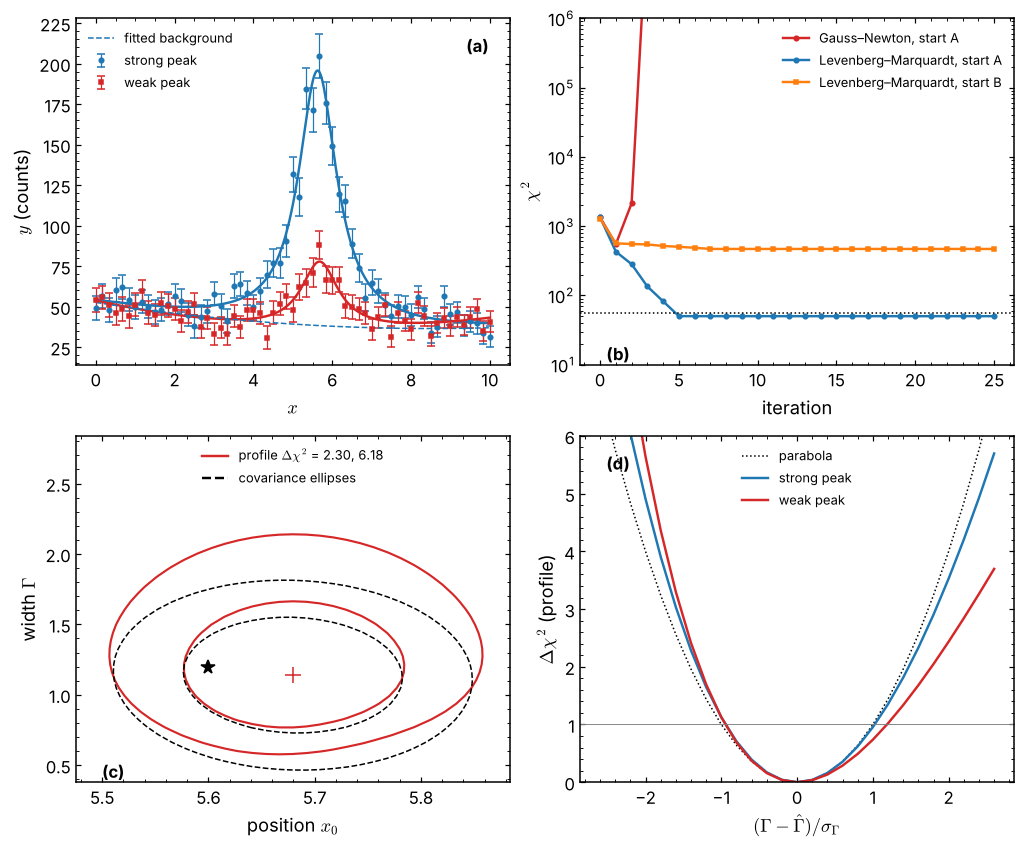

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
xf = np.linspace(0, 10, 400)
ax.errorbar(x, y, s, fmt="o", ms=3, color="C0", lw=0.8, label="strong peak")
ax.errorbar(x, y_w, s_w, fmt="s", ms=3, color="C3", lw=0.8, label="weak peak")
ax.plot(xf, model(xf, *fit.params), "C0")
ax.plot(xf, model(xf, *fit_w.params), "C3")
bg = fit.params.copy(); bg[3] = 0
ax.plot(xf, model(xf, *bg), "C0--", lw=1, label="fitted background")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$ (counts)")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
with np.errstate(all="ignore"):
    ax.semilogy(np.arange(hist_gn.size), np.where(np.isfinite(hist_gn), hist_gn, np.nan), "o-", ms=3, color="C3", label="Gauss–Newton, start A")
ax.semilogy(np.arange(hist_lmA.size), hist_lmA, "o-", ms=3, color="C0", label="Levenberg–Marquardt, start A")
ax.semilogy(np.arange(hist_lmB.size), hist_lmB, "s-", ms=3, color="C1", label="Levenberg–Marquardt, start B")
ax.axhline(fit.dof, color="k", ls=":", lw=1)
ax.set_xlabel("iteration"); ax.set_ylabel(r"$\chi^2$")
ax.set_ylim(10, 1e6); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.06, y=0.06)

ax = axes[1, 0]
ax.contour(gx, gG, D, levels=[2.30, 6.18], colors="C3", linewidths=1.4)
ax.contour(gx, gG, D_lin, levels=[2.30, 6.18], colors="k", linestyles="--", linewidths=1)
ax.plot(fit_w.params[4], fit_w.params[5], "C3+", ms=10)
ax.plot(p_weak[4], p_weak[5], "k*", ms=9)
ax.plot([], [], "C3", label=r"profile $\Delta\chi^2$ = 2.30, 6.18")
ax.plot([], [], "k--", label="covariance ellipses")
ax.set_xlabel(r"position $x_0$"); ax.set_ylabel(r"width $\Gamma$")
ax.set_ylim(gG[0], gG[-1] + 0.45)
ax.legend(loc="upper center", fontsize=8.5, framealpha=1); ep.panel_label(ax, "(c)", x=0.06, y=0.06)

ax = axes[1, 1]
ax.plot(z, z**2, "k:", lw=1, label="parabola")
ax.plot(z, prof["strong"], "C0", label="strong peak")
ax.plot(z, prof["weak"], "C3", label="weak peak")
ax.axhline(1, color="0.5", lw=0.6)
ax.set_xlabel(r"$(\Gamma - \hat\Gamma)/\sigma_\Gamma$"); ax.set_ylabel(r"$\Delta\chi^2$ (profile)")
ax.set_ylim(0, 6); ax.legend(loc="upper center", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.06)
plt.show()

**(a)** Simulated data for the strong and weak peaks with the fitted curves;
dashed: the fitted background of the strong-peak data. **(b)** $\chi^2$ during
the iteration (dotted: the number of degrees of freedom). Gauss–Newton
diverges from start A; Levenberg–Marquardt converges from it, and from start
B to a local minimum. **(c)** Joint 68 % and 95 % regions for $x_0$ and
$\Gamma$ of the weak peak: profile contours against the ellipses from
$C_p$; the star is the true value. **(d)** Profile $\Delta\chi^2$ of the
width against the parabola of linear theory.

## Summary

* Nonlinear models are fitted iteratively. Levenberg–Marquardt is robust
  where Gauss–Newton diverges, but neither can distinguish a local minimum
  from the global one.
* Take starting values from a plot of the data, and confirm the minimum by
  restarting from different points; always plot the fit over the data.
* The covariance $(J^TWJ)^{-1}$ at the minimum is the linearised result. The
  correlation matrix often reflects the physics of the model and must be
  kept for derived quantities.
* The profile $\Delta\chi^2 = 1$ interval (2.30 for two parameters jointly)
  does not depend on the linearisation. Where it differs from
  $\pm\sigma$, quote it.
* Derived quantities can be obtained by propagation with the full
  covariance or, equivalently, by reparametrising the model.
* Check coverage by simulation when the data are weak.

## References

* Y. Avni, "Energy spectra of X-ray clusters of galaxies", *Astrophys. J.*
  **210**, 642 (1976).
* F. James, *Statistical Methods in Experimental Physics*, 2nd ed. (World
  Scientific, 2006).
* K. Levenberg, "A method for the solution of certain non-linear problems in
  least squares", *Q. Appl. Math.* **2**, 164 (1944).
* D. W. Marquardt, "An algorithm for least-squares estimation of nonlinear
  parameters", *J. Soc. Ind. Appl. Math.* **11**, 431 (1963).
* W. H. Press, S. A. Teukolsky, W. T. Vetterling and B. P. Flannery,
  *Numerical Recipes*, 3rd ed. (Cambridge University Press, 2007).
* J. Tellinghuisen, "Statistical error propagation", *J. Phys. Chem. A*
  **105**, 3917 (2001).

## Exercises

1. Fit the strong-peak data with the background written in powers of $x$
   instead of $u = x - 5$. Compare the correlation matrices and the number
   of iterations.
2. Replace the Lorentzian by a Gaussian of the same width. Which parameter
   correlations change, and why?
3. Reduce the peak height step by step from 150 to 20 and plot, against the
   height, the asymmetry of the profile interval of $\Gamma$ and the
   fraction of random starting points that find the global minimum.
4. Find the profile $\Delta\chi^2 = 1$ interval of the area for the weak
   peak, using the reparametrised model, and compare it with $\pm\sigma_A$.
5. Derive the Gauss–Newton step from the condition
   $\partial\chi^2/\partial\boldsymbol\delta = 0$ for the linearised model.

---

**Previous:** [13. Fit parameters and their covariance](13_fit_parameter_covariance.ipynb) &nbsp;·&nbsp; **Next:** [15. Fitting counts: maximum likelihood](15_maximum_likelihood_fitting.ipynb)